# Chapter 4 Media Mix modeling homework

In [10]:
import pandas as pd
import numpy as np

## 1. Load the data file

In [11]:
df = pd.read_csv('sales_ads_use.csv')

In [12]:
df['year_month'] = df['year'].astype(str) + '-' + df['month'].astype(str).str.zfill(2)

In [13]:
df.columns

Index(['year', 'month', 'sales', 'newspaper', 'magazine', 'radio', 'tv',
       'year_month'],
      dtype='object')

## 2. Plot the channel spending

In [14]:
ax.set_xticks(ax.get_xticks()[::4])  # Show every 4th label
fig.autofmt_xdate()  # Auto-format for better appearance
fig.tight_layout()
fig.show()

C:\Users\dong__000\AppData\Local\Temp\ipykernel_3812\172814469.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


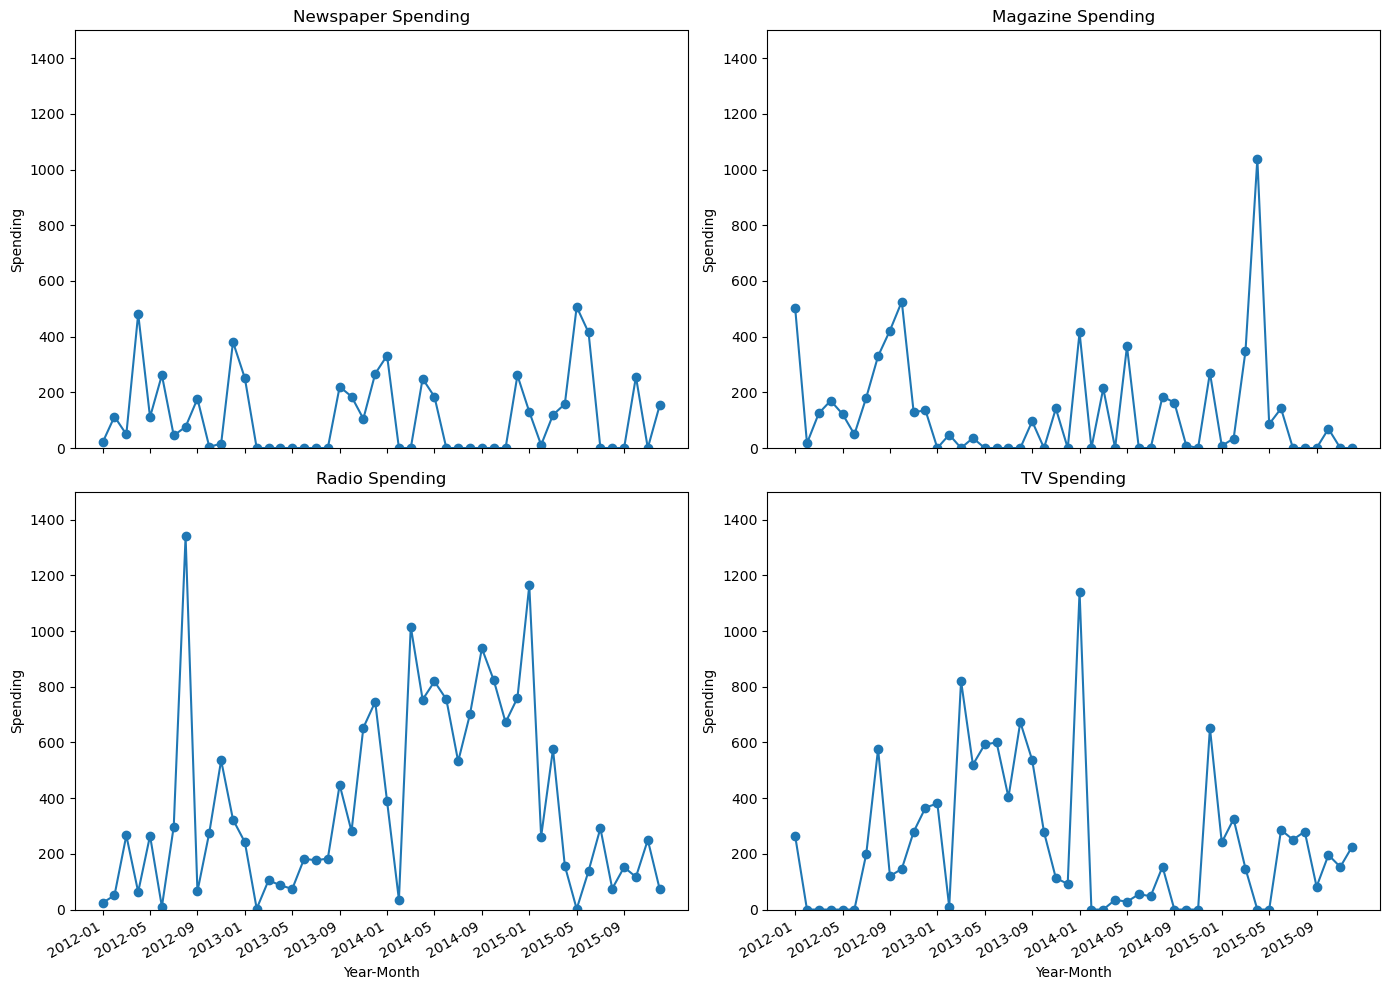

In [15]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(14, 10))
channels = ['newspaper', 'magazine', 'radio', 'tv']
titles = ['Newspaper Spending', 'Magazine Spending', 'Radio Spending', 'TV Spending']

for i, ax in enumerate(axs.flatten()):
    ax.plot(df['year_month'], df[channels[i]], marker='o')
    ax.set_title(titles[i])
    ax.set_xlabel('Year-Month')
    ax.set_ylabel('Spending')
    ax.set_ylim(0, 1500)  # Set y-limits to 110% of max value
    ax.tick_params(axis='x', rotation=45)
    ax.set_xticks(ax.get_xticks()[::4])  # Show every 4th label
    fig.autofmt_xdate()  # Auto-format for better appearance


plt.tight_layout()
plt.show()

## 3. Re-estimate the model with different lambda values

In [16]:
df.head()

,year,month,sales,newspaper,magazine,radio,tv,year_month
0,2012,1,2381,20,504,24,265,2012-01
1,2012,2,1765,113,17,51,0,2012-02
2,2012,3,2072,49,125,266,0,2012-03
3,2012,4,2183,482,170,63,0,2012-04
4,2012,5,2085,111,122,265,0,2012-05


In [17]:
# import the package for regression analysis
import statsmodels.api as sm

# define the independent variables (ads) and dependent variable (sales)
MM = df[['newspaper', 'magazine', 'radio', 'tv']]
y = df['sales']



In [18]:
def getAdsStockMatrix(MM, lambd):
    """
    Calculate the ad stock matrix for each variable in X (excluding 'const').
    G(t) = G(t-1) + lambda * M(t)
    Args:
        X (pd.DataFrame): DataFrame with columns ['const', 'newspaper', 'magazine', 'radio', 'tv']
        lambd (float): Discount factor (lambda)
    Returns:
        pd.DataFrame: Ad stock matrix (same shape as X, but without 'const')
    """
    stock = pd.DataFrame(index=MM.index, columns=MM.columns)
    for col in MM.columns:
        G = []
        prev = 0
        for m in MM[col]:
            g = lambd * prev +  m
            G.append(g)
            prev = g
        stock[col] = G
    return stock

In [19]:
# run regression models using different lambda values for calculating ad stock
r2_scores = []
lambdas = np.arange(0.1, 1.0, 0.1)
for lambd in lambdas:
    GG = getAdsStockMatrix(MM, lambd)
    X_GG = sm.add_constant(GG)
    model = sm.OLS(y, X_GG).fit()
    r2_scores.append(model.rsquared)


print("R^2 scores for different lambda values:", r2_scores)


R^2 scores for different lambda values: [0.5848194868900738, 0.5539248957124023, 0.5113825169967692, 0.45927276279024265, 0.4009982370714714, 0.3418242124335764, 0.2886547314064225, 0.24615391597472136, 0.20411362100409935]
